2026.10.28 一致性修订：请 Restart Kernel & Run All。初始化会验证当前 embedding→特征→预测→概率；旧 niche 缓存不再复用，旧图输出已清空。Deployment 最佳模型用法保持不变。


# NPC external validation — UNI2 A5 paired_v2 Hist2Pheno

This notebook shows **patient1** only (`20210809-C-AH4199551`).

Two HE slides, StarDist nuclei, **no cell-type ground truth**. StarDist detections were exported at probability 0.01. On both slides the histogram is flat from about 0.30 to 0.40 and then rises into the nucleus mode (peak near 0.75). Predictions below keep nuclei with **probability ≥ 0.40** and rebuild the k=8 neighborhood on that subset. The unfiltered run remains in the directory without the `_prob0.40` suffix.
This notebook applies the 2026-11-11 UNI2 retrain **A5** `best_mlp_gpu.pt` (fold 1; A2 trunk, L12 CE/NLL = 1, spatial k=8 mean, no gate). Pooled OOF L2 macro AUROC on the training cohorts was 0.8894. The unfiltered A5 predictions stay in `pred_uni2_A5_bestmlp_paired_v2_seed42`. The published UNI maps stay in `Pred_visual_npc.ipynb`.

OME `PhysicalSize` is **0.465 µm/px**. A native 14 px crop is **6.51 µm**. UNI2 training crops are **7 µm** (14 px at 0.5 µm/px), so extraction rescales by `0.465/0.5 ≈ 0.930` and then takes a 14 px class token. StarDist centroids stay full-resolution HE pixels and are scaled with the image.

Outputs, separate from the UNI trees:

- `data/Visium/NPC/project_all_UNI2/{sample}/ImgEmbeddings_all_stardist/sc_pth_14_14/`
- `data/Visium/NPC/pred_uni2_A5_bestmlp_paired_v2_seed42_prob{threshold}/{sample}/{sample}_stardist_pred.h5ad` — the `prob` suffix is `STAR_PROB_MIN` to two decimals (`0.40` stays in the existing folder; `0` uses the unsuffixed unfiltered folder)

Run `CUDA_DEVICE=0 bash code/External_val/NPC/demo_uni2_A5.sh predict` on a free GPU, then **Restart Kernel & Run All**. The setup cell does not score. UNI2 `.pth` files are already under `project_all_UNI2`. There is no ROC.


## Run this A5 checkpoint

`demo.sh` is the UNI run (`patch_size=16`, `project_all_UNI`). This script applies the paired_v2 A5 weight. Pick a free GPU with `CUDA_DEVICE`. A finished sample is skipped when the checkpoint hash matches.

```bash
bash code/External_val/NPC/demo_uni2_A5.sh dry-run
CUDA_DEVICE=0 bash code/External_val/NPC/demo_uni2_A5.sh predict
# one slide: SAMPLE=20210809-C-AH4199551 CUDA_DEVICE=0 bash code/External_val/NPC/demo_uni2_A5.sh predict
```


In [1]:
import sys
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt

mpl.rcParams["pdf.fonttype"] = 42  # TrueType; PDF text stays editable
mpl.rcParams["ps.fonttype"] = 42


REPO = Path("/home/lingyu/ssd2/Python/Hist2Pheno")
# 2026.10.28, explicit checkout override / Farm 可设 HIST2PHENO_REPO
import os
if os.environ.get("HIST2PHENO_REPO"):
    REPO = Path(os.environ["HIST2PHENO_REPO"]).expanduser().resolve()
if not (REPO / "code").is_dir():
    REPO = Path("/nobackup2/users/lingyu/Python/Hist2Pheno")
sys.path.insert(0, str(REPO / "code"))
sys.path.insert(0, str(REPO / "code" / "External_val" / "NPC"))

from npc_figures import (
    C2L_TYPES,
    STACK_ORDER,
    c2l_palette,
    configure_figure_dpi,
    draw_spot_circles,
    draw_tls,
    group_fraction,
    keep_leftmost_foci,
    legend_handles,
    load_tls_xy,
    map_l2,
    nuclei_in_contours,
    save_figure,
    tls_score_row,
    tls_smooth_contours,
)

from Hist2Pheno_pkg.external_validation import ExternalCohort

CKPT = (
    REPO
    / "data/PanCancer/result_uni2_A5_l12_links_1_paired_v2_seed42"
    / "cross_dataset_cv/A5_l12_links_1/best_mlp_gpu.pt"
)


STAR_PROB_MIN = 0.00  # valley between the prob=0.01 tail and the nucleus mode


# 2026.10.28, one prediction tree per cutoff / 0.40 仍写原目录，其它阈值另存
_pred_base = "pred_uni2_A5_bestmlp_paired_v2_seed42"
pred_dirname = _pred_base if float(STAR_PROB_MIN) <= 0 else f"{_pred_base}_prob{float(STAR_PROB_MIN):.2f}"
_cohort = ExternalCohort(
    name="NPC",
    data_root=REPO / "data" / "Visium" / "NPC",
    repo=REPO,
    patch_size=14,
    method="UNI2",
    embedding_dirname="project_all_UNI2",
    pred_dirname=pred_dirname,
    checkpoint=CKPT,
    project_tag="project_all_UNI2",
)
PRED_ROOT = _cohort.pred_root
composition_table = _cohort.composition_table
discover_samples = _cohort.discover_samples
geometry = _cohort.geometry
sample_paths = _cohort.sample_paths
ensure_l2_probs = _cohort.ensure_l2_probs
plot_spatial = _cohort.plot_spatial
plot_composition = _cohort.plot_composition
# Re-run the plot cell after changing these. Notebook display uses DPI; PNG uses SAVE_DPI; PDF is Type 42 vector.
SAVE_FIGURES = True
FIGSIZE = (17.2, 6.6)
DPI = 200
SAVE_DPI = 300
configure_figure_dpi(save_dpi=SAVE_DPI, plot_dpi=DPI)
HE_MAX_SIDE = 1400
MARKER_PX = 1.2
samples = discover_samples()
samples = [s for s in samples if s == "20210809-C-AH4199551"]
print("notebook shows patient1 only:", samples)
if not samples:
    raise RuntimeError("patient1 20210809-C-AH4199551 was not discovered")
print(f"StarDist probability >= {STAR_PROB_MIN:.2f}")
print(f"checkpoint {CKPT.name} exists={CKPT.is_file()}")
print(f"pred root {PRED_ROOT}")
for sample in samples:
    g = geometry(sample)
    print(
        f"{sample}  mpp={g['mpp_um']:.4f} µm/px  "
        f"native14={g['patch_um_if_native_16px']:.2f} µm  "
        f"after rescale={g['patch_um_after_rescale']:.1f} µm  "
        f"scale={g['scale']:.4f}"
    )
    p = sample_paths(sample)
    print(f"  embeddings: {p['emb']}")
    print(f"  pred exists: {p['pred'].is_file()}  {p['pred']}")

# Do not score here. Run demo_uni2_A5.sh predict first, then Restart Kernel & Run All.
import os as _pipeline_os
_pipeline_os.environ["STAR_PROB_MIN"] = "0" if float(STAR_PROB_MIN) <= 0 else f"{float(STAR_PROB_MIN):.2f}"
_missing = [s for s in samples if not sample_paths(s)["pred"].is_file()]
if _missing:
    raise FileNotFoundError(
        "No A5 predictions for "
        + ", ".join(_missing)
        + ". Run: CUDA_DEVICE=0 bash code/External_val/NPC/demo_uni2_A5.sh predict"
    )


notebook shows patient1 only: ['20210809-C-AH4199551']
StarDist probability >= 0.00
checkpoint best_mlp_gpu.pt exists=True
pred root /home/lingyu/ssd2/Python/Hist2Pheno/data/Visium/NPC/pred_uni2_A5_bestmlp_paired_v2_seed42
20210809-C-AH4199551  mpp=0.4651 µm/px  native14=6.51 µm  after rescale=7.0 µm  scale=0.9302
  embeddings: /home/lingyu/ssd2/Python/Hist2Pheno/data/Visium/NPC/project_all_UNI2/20210809-C-AH4199551/ImgEmbeddings_all_stardist/sc_pth_14_14
  pred exists: True  /home/lingyu/ssd2/Python/Hist2Pheno/data/Visium/NPC/pred_uni2_A5_bestmlp_paired_v2_seed42/20210809-C-AH4199551/20210809-C-AH4199551_stardist_pred.h5ad


In [2]:
from IPython.display import Image, display

missing = [s for s in samples if not sample_paths(s)["pred"].is_file()]
if missing:
    raise FileNotFoundError(
        "No UNI2 predictions yet for "
        + ", ".join(missing)
        + ". Run: CUDA_DEVICE=0 bash code/External_val/NPC/demo_uni2_A5.sh predict"
    )

comp = composition_table(samples)

for head in ("L1", "L12", "L2"):
    sub = comp.loc[comp["head"] == head].copy()
    order = sub.groupby("class")["fraction"].max().sort_values(ascending=False).index
    wide = (
        sub.pivot_table(index="class", columns="sample", values=["fraction", "n", "mean_conf"])
        .reindex(order)
    )
    print(f"\n===== {head} =====")
    display(wide.round(3))


[h5ad] load embeddings /home/lingyu/ssd2/Python/Hist2Pheno/data/Visium/NPC/project_all_UNI2/20210809-C-AH4199551/ImgEmbeddings_all_stardist/sc_pth_14_14
  Using specified coordinates: centroid_x, centroid_y
  Building KDTree for embeddings: 142,184 points
  KDTree matched 142,184 / 142,184 cells (100.00%).
[h5ad] 20210809-C-AH4199551: 142,184/142,184 nuclei, 1536 features
Loading best model for StarDist prediction...
  Checkpoint file: /home/lingyu/ssd2/Python/Hist2Pheno/data/PanCancer/result_uni2_A5_l12_links_1_paired_v2_seed42/cross_dataset_cv/A5_l12_links_1/best_mlp_gpu.pt
  Inferred hidden_dims from checkpoint: [768, 384, 192]
✓ StarDist model loaded

===== L1 =====


,fraction,mean_conf,n
sample,20210809-C-AH4199551,20210809-C-AH4199551,20210809-C-AH4199551
class,,,
Epithelial,0.730,0.849,103736.0
Immune,0.242,0.655,34396.0
Endothelial,0.021,0.559,3001.0
Stromal,0.007,0.451,1007.0
Neural,0.000,0.454,44.0



===== L12 =====


,fraction,mean_conf,n
sample,20210809-C-AH4199551,20210809-C-AH4199551,20210809-C-AH4199551
class,,,
Tumor,0.549,0.832,78003.0
Myeloid,0.308,0.605,43729.0
Epithelial,0.101,0.602,14318.0
T_cell,0.023,0.433,3250.0
Stromal,0.011,0.398,1635.0
Endothelial,0.008,0.396,1198.0
B_Plasma,0.000,0.373,51.0



===== L2 =====


,fraction,mean_conf,n
sample,20210809-C-AH4199551,20210809-C-AH4199551,20210809-C-AH4199551
class,,,
Tumor,0.455,0.753,64632.0
DC,0.336,0.566,47802.0
Epithelial,0.134,0.544,19066.0
DCIS,0.035,0.544,4989.0
Endothelial,0.013,0.321,1875.0
Tregs,0.008,0.314,1123.0
Myofibroblast,0.005,0.317,667.0
Neutrophil,0.004,0.261,550.0


[plot] 20210809-C-AH4199551  nuclei=142,184  neighbor=13.1px  figsize=(17.2, 12.54)  dpi=200  marker_px=1.2  rows=HE+points
[plot] /home/lingyu/ssd2/Python/Hist2Pheno/data/Visium/NPC/pred_uni2_A5_bestmlp_paired_v2_seed42/figures/20210809-C-AH4199551_spatial_L1_L12_L2.pdf  save_dpi=300


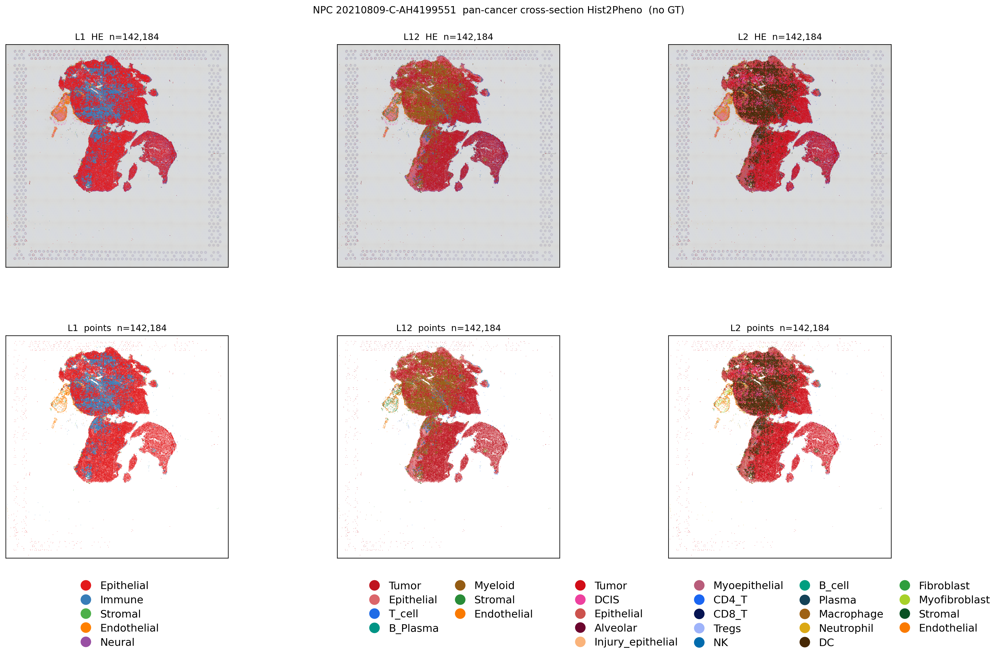

In [3]:
import matplotlib.pyplot as plt

for fig in plot_spatial(
    samples,
    figsize=FIGSIZE,
    dpi=DPI,
    he_max_side=HE_MAX_SIDE,
    marker_px=MARKER_PX,
    save=SAVE_FIGURES,
    save_dpi=SAVE_DPI,
):
    display(fig)
    plt.close(fig)


[plot] /home/lingyu/ssd2/Python/Hist2Pheno/data/Visium/NPC/pred_uni2_A5_bestmlp_paired_v2_seed42/figures/composition_L1.pdf  save_dpi=300
[plot] /home/lingyu/ssd2/Python/Hist2Pheno/data/Visium/NPC/pred_uni2_A5_bestmlp_paired_v2_seed42/figures/composition_L12.pdf  save_dpi=300
[plot] /home/lingyu/ssd2/Python/Hist2Pheno/data/Visium/NPC/pred_uni2_A5_bestmlp_paired_v2_seed42/figures/composition_L2.pdf  save_dpi=300


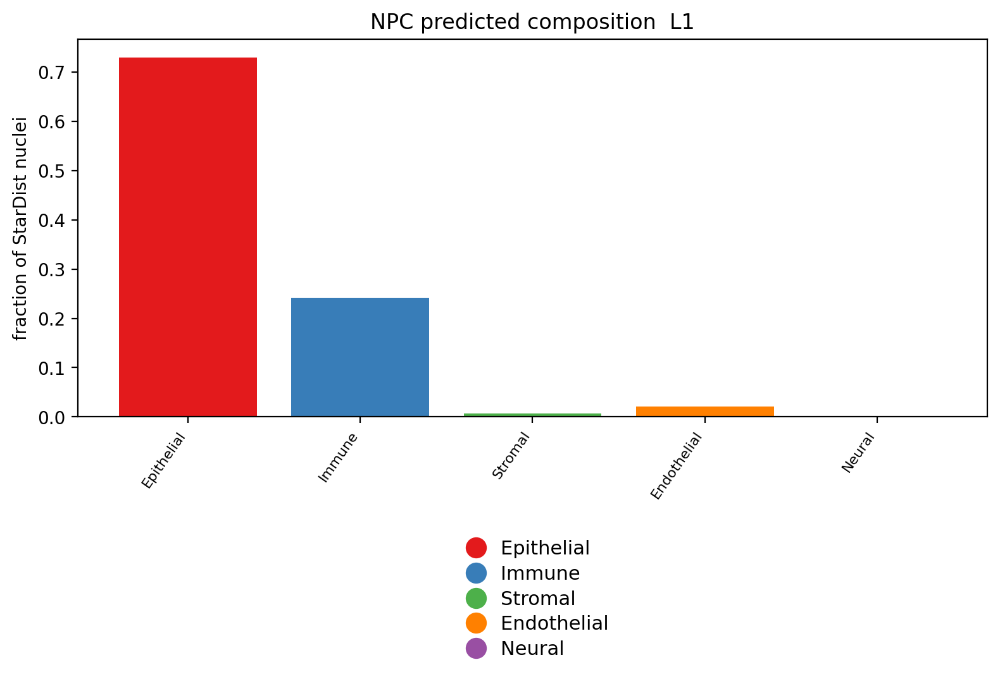

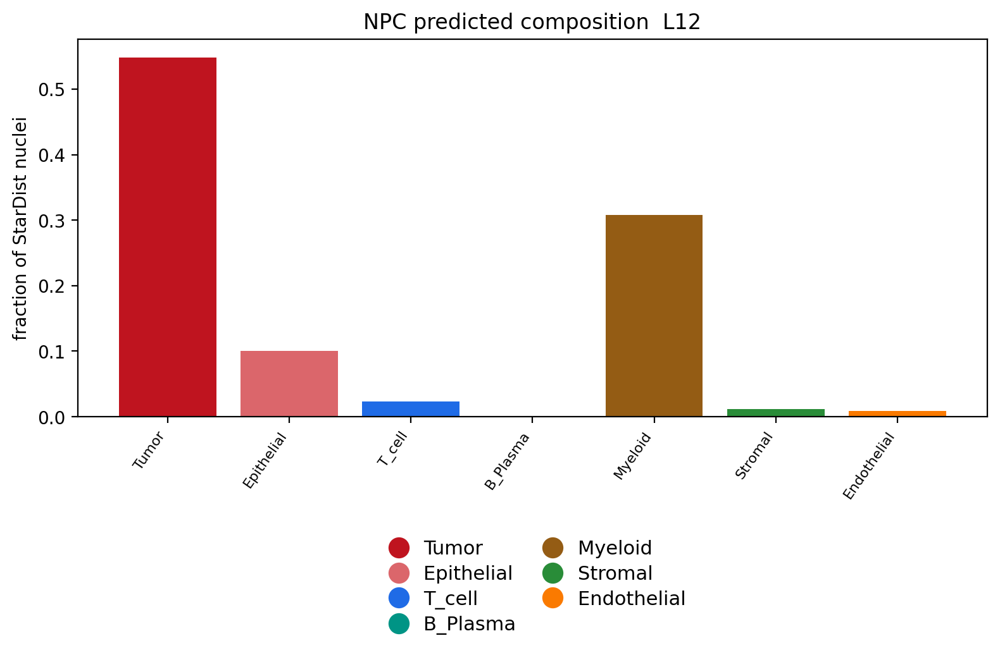

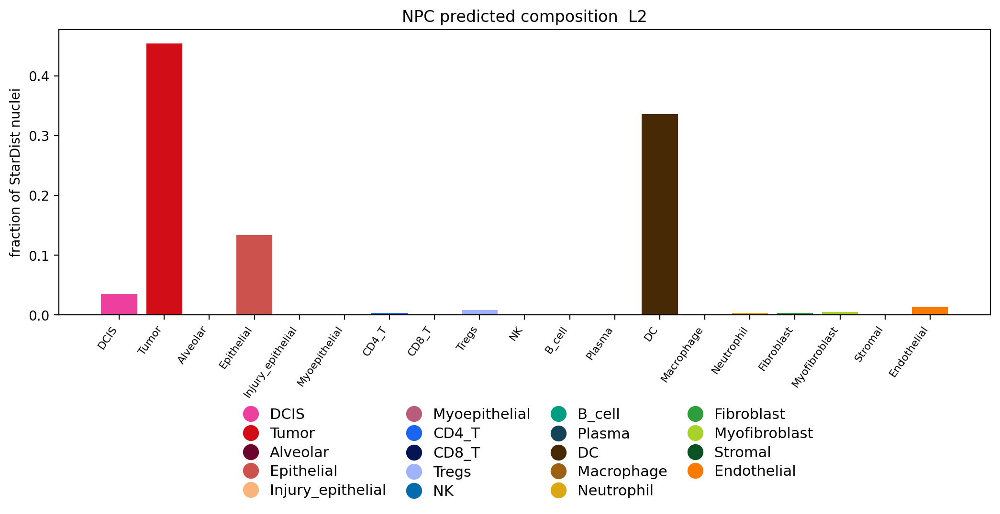

In [4]:
for fig in plot_composition(samples, save=SAVE_FIGURES, dpi=DPI, save_dpi=SAVE_DPI):
    display(fig)
    plt.close(fig)


## Resolution from Visium spot to single cell

Same mapping as `Fig2_Fig3_panels.ipynb` (Fig. 3b). Each StarDist nucleus goes to the **nearest** Visium spot and is kept only inside that spot’s capture disc (`spot_diameter_fullres / 2`), via `Hist2Pheno_pkg/nuclei_to_spots.py`.

Three spatial panels: **single-nucleus L2**, **pseudo-spot** (majority predicted L2 in the disc), **cell2location** (argmax of the 7 abundances). Patient1 uses `Annotation/sp.obs.csv` (`AH4199551`); patient2 uses `Annotation/AJ_sp.obs.csv` (`AJ3037946`). The next cell stacks Hist2Pheno vs pseudo-spot vs cell2location on the same 7-type vocabulary.


cell2location ['sp.obs.csv', 'AJ_sp.obs.csv'] rows 2420 samples ['AH4199551', 'AJ3037946']
cell2location AH4199551: 1,331 / 1,331 in-tissue spots matched


,group,Hist2Pheno,pseudo_spot,cell2location
0,tumor,0.4546,0.4966,0.5282
1,normal,0.1705,0.1405,0.0594
2,fibroblast,0.0086,0.0158,0.1067
3,T,0.0040,0.0038,0.0624
4,Treg,0.0079,0.0023,0.0038
5,B,0.0009,0.0000,0.1803
6,Myeloid,0.3403,0.3201,0.0594
7,other,0.0132,0.0210,0.0000


NPC 20210809-C-AH4199551 (patient1): nuclei 142,184, in-tissue spots 1,331, pitch 214.0 px, capture radius 69.7 px, nuclei in a spot 52,669 / 142,184, spots with nuclei 1,331
/home/lingyu/ssd2/Python/Hist2Pheno/data/Visium/NPC/pred_uni2_A5_bestmlp_paired_v2_seed42/figures/20210809-C-AH4199551_nuclei_vs_visium.pdf


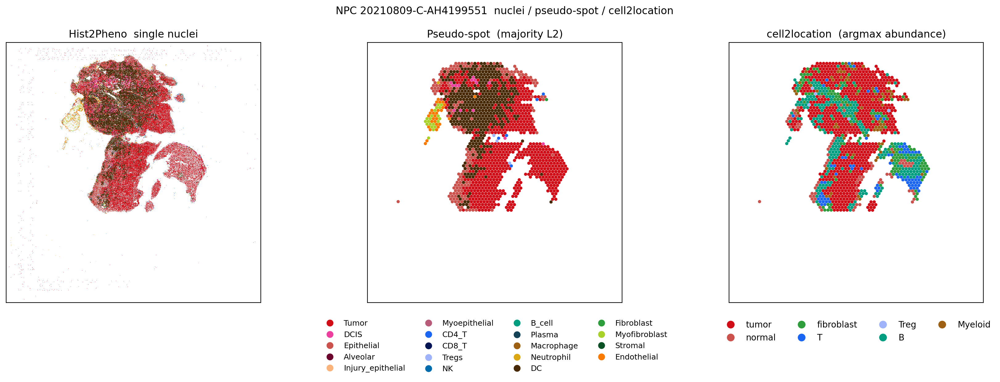

In [5]:
import json

import anndata as ad
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.spatial import cKDTree

from Hist2Pheno_pkg.nuclei_to_spots import nuclei_to_spots
from Hist2Pheno_pkg.plotting_palettes import get_palette

L2_PALETTE = get_palette("pancancer", "fine")
L2_NAMES = list(L2_PALETTE)
SAMPLE_TO_VISIUM = {
    "20210809-C-AH4199551": "patient1",
    "20210809-D-AJ3037946": "patient2",
}
SAMPLE_TO_C2L = {
    "20210809-C-AH4199551": "AH4199551",
    "20210809-D-AJ3037946": "AJ3037946",
}
NPC_DATA = REPO / "data" / "Visium" / "NPC"
C2L_FILES = [
    NPC_DATA / "Annotation" / "sp.obs.csv",
    NPC_DATA / "Annotation" / "AJ_sp.obs.csv",
]
fig_dir = PRED_ROOT / "figures"
fig_dir.mkdir(parents=True, exist_ok=True)

# cell2location types, coloured like the matching pan-cancer L2 classes.
C2L_COLOR = c2l_palette(L2_PALETTE)
missing = [p for p in C2L_FILES if not p.is_file()]
if missing:
    raise FileNotFoundError(missing)
c2l_obs = pd.concat([pd.read_csv(p, index_col=0) for p in C2L_FILES], axis=0)
c2l_obs.index = c2l_obs.index.astype(str)
print(
    "cell2location",
    [p.name for p in C2L_FILES],
    "rows",
    len(c2l_obs),
    "samples",
    sorted(c2l_obs["sample"].astype(str).unique()),
)

nucleus_s = max(0.12, (float(MARKER_PX) * 72.0 / float(DPI)) ** 2 * 0.35)
spot_maps = {}

for sample in samples:
    visium_id = SAMPLE_TO_VISIUM.get(sample)
    if visium_id is None:
        print(f"[skip] {sample}: no patient1/patient2 Visium folder mapping")
        continue
    npc_dir = NPC_DATA / visium_id
    pred_path = sample_paths(sample)["pred"]
    if not pred_path.is_file():
        raise FileNotFoundError(pred_path)
    scale = json.loads((npc_dir / "scalefactors_json.json").read_text())
    radius_px = float(scale["spot_diameter_fullres"]) / 2
    pos = pd.read_csv(
        npc_dir / "tissue_positions_list.csv",
        header=None,
        names=["barcode", "in_tissue", "array_row", "array_col", "pxl_row", "pxl_col"],
    )
    pos = pos.loc[pos["in_tissue"] == 1].reset_index(drop=True)
    pos["barcode"] = pos["barcode"].astype(str)
    spot_xy = pos[["pxl_col", "pxl_row"]].to_numpy(dtype=np.float64)
    pitch_px = float(np.median(cKDTree(spot_xy).query(spot_xy, k=2)[0][:, 1]))
    npc = ad.read_h5ad(pred_path)
    npc_xy = np.asarray(npc.obsm["spatial_HE"], dtype=np.float64)
    npc_lab = npc.obs["pred_CT"].astype(str).to_numpy()
    captured = nuclei_to_spots(
        npc_xy, spot_xy, radius_px, shape="circle",
        labels=npc_lab, class_names=L2_NAMES,
    )
    counts = captured["n_nuclei"]
    used = counts > 0
    npc_spots = pos.loc[used].copy()
    npc_spots["pixel_x"] = spot_xy[used, 0]
    npc_spots["pixel_y"] = spot_xy[used, 1]
    npc_spots["n_nuclei"] = counts[used]
    npc_spots["dominant_l2"] = captured["dominant"][used]
    npc_spots["dominant_group"] = map_l2(npc_spots["dominant_l2"])
    for i, name in enumerate(L2_NAMES):
        npc_spots[f"n_{name}"] = captured["class_counts"][used, i]
        npc_spots[f"fraction_{name}"] = captured["class_counts"][used, i] / counts[used]
    npc_spots.to_csv(fig_dir / f"{sample}_visium_composition.csv", index=False)

    nuc_group = map_l2(npc_lab)
    h2p_frac = group_fraction(nuc_group)
    pseudo_frac = group_fraction(npc_spots["dominant_group"].to_numpy())

    c2l_id = SAMPLE_TO_C2L.get(sample)
    c2l_xy = c2l_lab = None
    c2l_frac = None
    if c2l_id is not None:
        sub = c2l_obs.loc[c2l_obs["sample"].astype(str) == str(c2l_id)].copy()
        hit = pos["barcode"].isin(sub.index)
        aligned = sub.reindex(pos.loc[hit, "barcode"])
        raw = aligned[list(C2L_TYPES)].to_numpy(dtype=np.float64)
        ok = np.isfinite(raw).all(axis=1) & (raw.sum(axis=1) > 0)
        raw = raw[ok]
        c2l_xy = spot_xy[hit.to_numpy()][ok]
        c2l_lab = np.array(C2L_TYPES)[np.argmax(raw, axis=1)]
        c2l_frac = group_fraction(c2l_lab)
        print(
            f"cell2location {c2l_id}: {int(ok.sum()):,} / {int(hit.sum()):,} "
            f"in-tissue spots matched"
        )

    spot_maps[sample] = {
        "h2p": h2p_frac,
        "pseudo": pseudo_frac,
        "c2l": c2l_frac,
        "n_nuc": len(npc_lab),
        "n_spot": int(used.sum()),
        "n_c2l": 0 if c2l_lab is None else int(len(c2l_lab)),
    }
    frac = pd.DataFrame(
        {
            "group": list(STACK_ORDER),
            "Hist2Pheno": [h2p_frac[k] for k in STACK_ORDER],
            "pseudo_spot": [pseudo_frac[k] for k in STACK_ORDER],
            "cell2location": [
                float(c2l_frac[k]) if c2l_frac is not None else np.nan
                for k in STACK_ORDER
            ],
        }
    )
    frac.to_csv(fig_dir / f"{sample}_nuclei_vs_visium_fraction.csv", index=False)
    display(frac.round(4))
    print(
        f"NPC {sample} ({visium_id}): nuclei {len(npc_xy):,}, "
        f"in-tissue spots {len(spot_xy):,}, pitch {pitch_px:.1f} px, "
        f"capture radius {radius_px:.1f} px, "
        f"nuclei in a spot {int(captured['inside'].sum()):,} / {len(npc_xy):,}, "
        f"spots with nuclei {int(used.sum()):,}"
    )

    spot_draw_radius = 0.50 * pitch_px
    fig, axes = plt.subplots(1, 3, figsize=(16.8, 5.6), dpi=DPI)
    axes[0].set_title("Hist2Pheno  single nuclei")
    for name in L2_NAMES:
        mask = npc_lab == name
        if np.any(mask):
            axes[0].scatter(
                npc_xy[mask, 0], npc_xy[mask, 1], s=nucleus_s,
                c=[L2_PALETTE[name]], linewidths=0, rasterized=True,
            )
    draw_spot_circles(
        axes[1], spot_xy[used], npc_spots["dominant_l2"].to_numpy(),
        spot_draw_radius, L2_PALETTE, L2_NAMES,
    )
    axes[1].set_title("Pseudo-spot  (majority L2)")
    if c2l_xy is None:
        axes[2].text(0.5, 0.5, "no cell2location\nfor this slide", ha="center", va="center")
        axes[2].set_title("cell2location")
    else:
        draw_spot_circles(
            axes[2], c2l_xy, c2l_lab, spot_draw_radius, C2L_COLOR, C2L_TYPES,
        )
        axes[2].set_title("cell2location  (argmax abundance)")
    pad = pitch_px
    for ax in axes:
        ax.set_xlim(npc_xy[:, 0].min() - pad, npc_xy[:, 0].max() + pad)
        ax.set_ylim(npc_xy[:, 1].max() + pad, npc_xy[:, 1].min() - pad)
        ax.set_aspect("equal")
        ax.set_xticks([])
        ax.set_yticks([])
    present_l2 = [
        n for n in L2_NAMES
        if n in set(npc_lab) or n in set(npc_spots["dominant_l2"].astype(str))
    ]
    axes[1].legend(
        handles=legend_handles(present_l2, L2_PALETTE),
        frameon=False, fontsize=9, loc="upper center",
        bbox_to_anchor=(0.5, -0.04), ncol=4,
    )
    if c2l_lab is not None:
        present_c2l = [n for n in C2L_TYPES if n in set(c2l_lab)]
        axes[2].legend(
            handles=legend_handles(present_c2l, C2L_COLOR, markersize=9),
            frameon=False, fontsize=10, loc="upper center",
            bbox_to_anchor=(0.5, -0.04), ncol=4,
        )
    fig.suptitle(f"NPC {sample}  nuclei / pseudo-spot / cell2location", fontsize=12, y=1.02)
    fig.tight_layout()
    fig.subplots_adjust(bottom=0.16)
    if SAVE_FIGURES:
        save_figure(fig, fig_dir / f"{sample}_nuclei_vs_visium.pdf")
    display(fig)
    plt.close(fig)


### Stacked composition (same 7 types)

All three bars are **class proportions** on the same 7 cell2location types. Hist2Pheno = fraction of nuclei after mapping L2 → these types. Pseudo-spot = fraction of spots by majority mapped L2. cell2location = fraction of spots after converting per-spot abundances to a class (`argmax`). `other` is Endothelial / Neural (Hist2Pheno only).


/home/lingyu/ssd2/Python/Hist2Pheno/data/Visium/NPC/pred_uni2_A5_bestmlp_paired_v2_seed42/figures/NPC_hist2pheno_pseudospot_cell2location_stacked.pdf


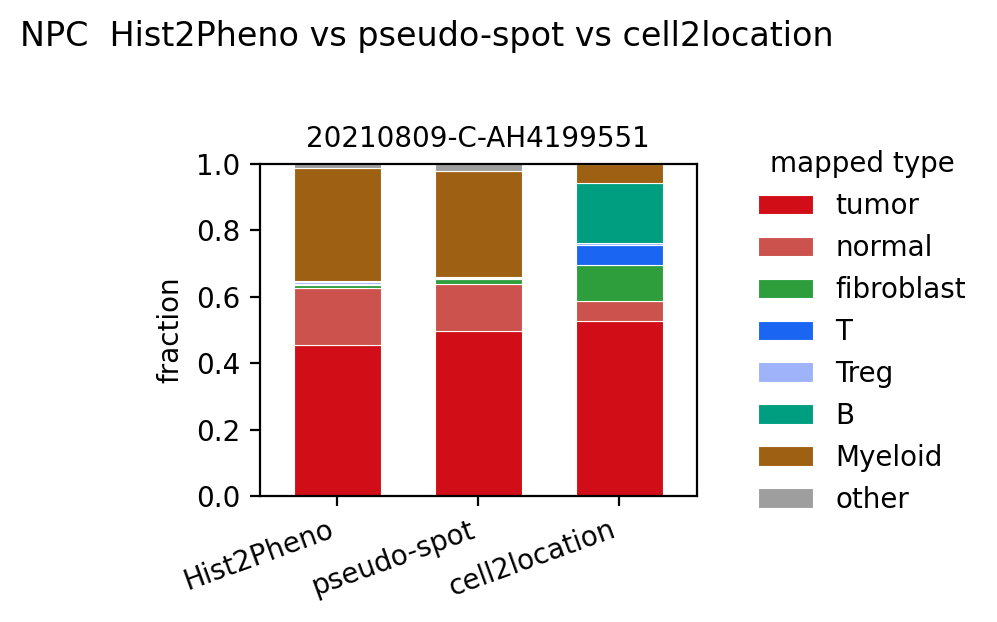

/home/lingyu/ssd2/Python/Hist2Pheno/data/Visium/NPC/pred_uni2_A5_bestmlp_paired_v2_seed42/figures/NPC_hist2pheno_pseudospot_cell2location_stacked.csv


sample     20210809-C-AH4199551                          
method               Hist2Pheno cell2location pseudo-spot
group                                                    
B                         0.001         0.180       0.000
Myeloid                   0.340         0.059       0.320
T                         0.004         0.062       0.004
Treg                      0.008         0.004       0.002
fibroblast                0.009         0.107       0.016
normal                    0.171         0.059       0.140
other                     0.013         0.000       0.021
tumor                     0.455         0.528       0.497

In [6]:
# 100% stacked class proportions: Hist2Pheno nuclei vs pseudo-spot majority vs cell2location argmax.
# Groups are the 7 cell2location types (+ other). Patient1: sp.obs.csv; patient2: AJ_sp.obs.csv.
methods = ("Hist2Pheno", "pseudo-spot", "cell2location")
method_key = {"Hist2Pheno": "h2p", "pseudo-spot": "pseudo", "cell2location": "c2l"}
samples_plot = [s for s in samples if s in spot_maps]
n_panel = max(len(samples_plot), 1)
fig, axes = plt.subplots(
    1, n_panel, figsize=(1.2 * n_panel + 1.8, 3.0), dpi=DPI, squeeze=False,
)
axes = axes[0]
for ax, sample in zip(axes, samples_plot):
    rec = spot_maps[sample]
    x = np.arange(len(methods))
    bottom = np.zeros(len(methods))
    for grp in STACK_ORDER:
        vals = []
        for m in methods:
            ser = rec[method_key[m]]
            vals.append(float(ser[grp]) if ser is not None else 0.0)
        vals = np.asarray(vals, dtype=float)
        if np.allclose(vals, 0.0):
            continue
        ax.bar(
            x, vals, bottom=bottom, width=0.62,
            color=C2L_COLOR[grp][:3], edgecolor="white", linewidth=0.4, label=grp,
        )
        bottom = bottom + vals
    ax.set_xticks(x)
    ax.set_xticklabels(methods, rotation=20, ha="right")
    ax.set_ylim(0, 1)
    ax.set_ylabel("fraction")
    extra = ""
    if rec["c2l"] is None:
        extra = "  (no cell2location)"
        ax.text(2, 0.5, "n/a", ha="center", va="center", fontsize=9, color="#888888")
    ax.set_title(f"{sample}{extra}", fontsize=10)
    ax.set_xlim(-0.55, 2.55)

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(
    handles, labels, loc="center left", bbox_to_anchor=(1.01, 0.5),
    frameon=False, fontsize=10, title="mapped type",
)
fig.suptitle("NPC  Hist2Pheno vs pseudo-spot vs cell2location", fontsize=12, y=1.02)
fig.tight_layout()
if SAVE_FIGURES:
    save_figure(fig, fig_dir / "NPC_hist2pheno_pseudospot_cell2location_stacked.pdf")
display(fig)
plt.close(fig)

rows = []
for sample, rec in spot_maps.items():
    for method, key in method_key.items():
        ser = rec[key]
        if ser is None:
            continue
        for grp in STACK_ORDER:
            rows.append(
                {"sample": sample, "method": method, "group": grp, "fraction": float(ser[grp])}
            )
stack_tab = pd.DataFrame(rows)
stack_path = fig_dir / "NPC_hist2pheno_pseudospot_cell2location_stacked.csv"
stack_tab.to_csv(stack_path, index=False)
print(stack_path)
display(stack_tab.pivot_table(index="group", columns=["sample", "method"], values="fraction").round(3))


## TLS annotation (patient1)

Expert Visium TLS barcodes in `data/Visium/NPC/Annotation/TLS_spot_label.csv` (36 spots on `AH4199551` / `20210809-C-AH4199551`). Each barcode is mapped through `patient1/tissue_positions_list.csv`. A Gaussian-smoothed capture disc around those spots gives a **smooth outline** of each TLS focus. **Only the three left-side foci are kept** (the two lower-right clusters are dropped). The zoom box is the bounding rectangle of the kept spots plus padding. Overview: black outline only. Zoom: black outline + Visium spots. Then Hist2Pheno L1 / L12 / L2 inside that zoom. The L1 / L12 / L2 legend lists only nuclei inside the black TLS outlines, not every nucleus in the zoom rectangle. A 100% stacked bar uses that same outline set.


TLS foci: 5 total, keep 3 leftmost (26 / 36 spots)
TLS 20210809-C-AH4199551: 26 spots, 3 smooth foci, pitch 214.0 px, zoom [5489:7896]×[6472:10755]  1120×1992 µm
/home/lingyu/ssd2/Python/Hist2Pheno/data/Visium/NPC/pred_uni2_A5_bestmlp_paired_v2_seed42/figures/20210809-C-AH4199551_TLS_HE_overview_zoom.pdf


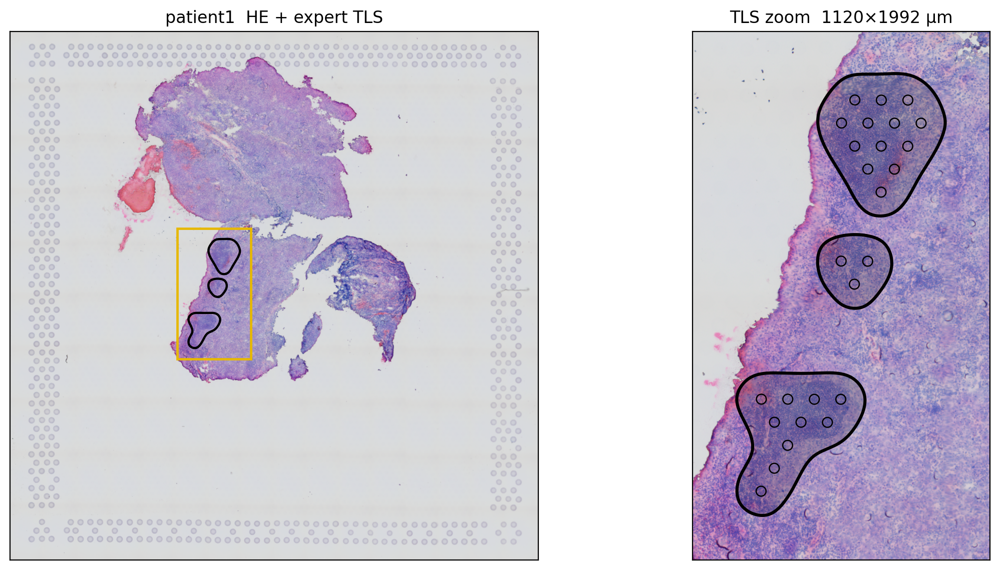

nuclei inside black TLS outline: 5,262 / zoom 22,134
/home/lingyu/ssd2/Python/Hist2Pheno/data/Visium/NPC/pred_uni2_A5_bestmlp_paired_v2_seed42/figures/20210809-C-AH4199551_TLS_ROI_spatial_L1_L12_L2.pdf


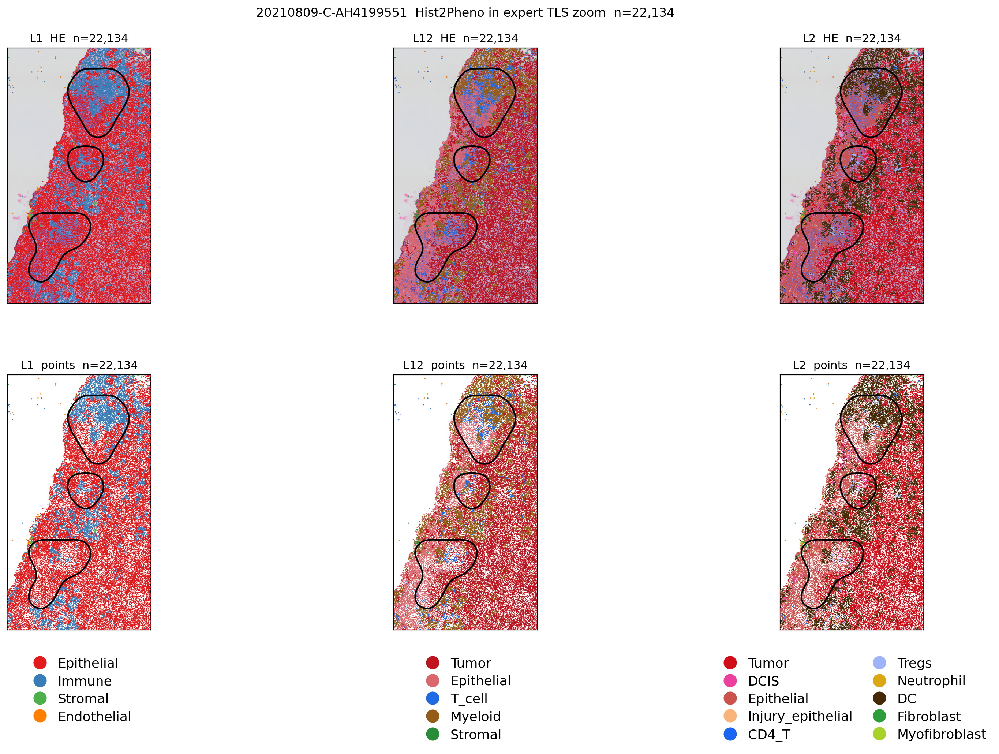

/home/lingyu/ssd2/Python/Hist2Pheno/data/Visium/NPC/pred_uni2_A5_bestmlp_paired_v2_seed42/figures/20210809-C-AH4199551_TLS_outline_stacked.pdf
/home/lingyu/ssd2/Python/Hist2Pheno/data/Visium/NPC/pred_uni2_A5_bestmlp_paired_v2_seed42/figures/20210809-C-AH4199551_TLS_outline_stacked.csv


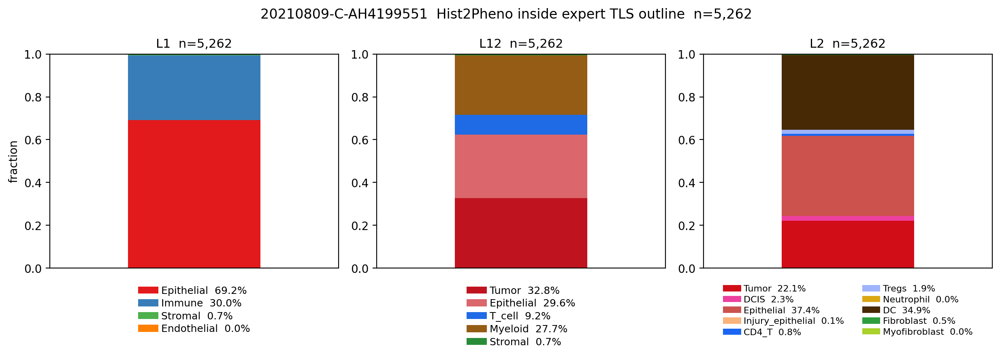

,head,class,n,fraction
0,L1,Epithelial,3643,0.692322
1,L1,Immune,1581,0.300456
2,L1,Stromal,37,0.007032
3,L1,Endothelial,1,0.000190
4,L12,Tumor,1725,0.327822
5,L12,Epithelial,1560,0.296465
6,L12,T_cell,485,0.092170
7,L12,Myeloid,1456,0.276701
8,L12,Stromal,36,0.006842
9,L2,Tumor,1161,0.220639


In [7]:
import anndata as ad
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display
from matplotlib.patches import Rectangle


from Hist2Pheno_pkg.panel_figures import (
    crop_he_rectangle,
    nuclei_in_rectangle,
    plot_pred_composition_stacked,
    plot_roi_pred_spatial,
)

TLS_SAMPLE = "20210809-C-AH4199551"
NPC_DATA = REPO / "data" / "Visium" / "NPC"
TLS_PATH = NPC_DATA / "Annotation" / "TLS_spot_label.csv"
VISIUM_DIR = NPC_DATA / "patient1"
fig_dir = PRED_ROOT / "figures"
fig_dir.mkdir(parents=True, exist_ok=True)

ROI_BOX = "#E6B800"
PAD_PITCH = 2.6
N_KEEP_LEFT = 3


tls_xy, tls_bc, pitch_px, spot_r_px = load_tls_xy(TLS_PATH, VISIUM_DIR)
keep = keep_leftmost_foci(tls_xy, pitch_px, n_keep=N_KEEP_LEFT)
tls_xy, tls_bc = tls_xy[keep], tls_bc[keep]
contours = tls_smooth_contours(tls_xy, disk_r=0.70 * pitch_px, sigma=0.45 * pitch_px)
paths = sample_paths(TLS_SAMPLE)
g = geometry(TLS_SAMPLE)
pad = PAD_PITCH * pitch_px
x0 = max(0.0, float(tls_xy[:, 0].min() - pad))
y0 = max(0.0, float(tls_xy[:, 1].min() - pad))
thumb, full_w, full_h = _cohort._he_thumbnail(paths["he"], max_side=HE_MAX_SIDE)
x1 = min(float(full_w), float(tls_xy[:, 0].max() + pad))
y1 = min(float(full_h), float(tls_xy[:, 1].max() + pad))
w_um = (x1 - x0) * g["mpp_um"]
h_um = (y1 - y0) * g["mpp_um"]
print(
    f"TLS {TLS_SAMPLE}: {len(tls_bc)} spots, {len(contours)} smooth foci, "
    f"pitch {pitch_px:.1f} px, zoom [{x0:.0f}:{x1:.0f}]×[{y0:.0f}:{y1:.0f}]  "
    f"{w_um:.0f}×{h_um:.0f} µm"
)

fig, axes = plt.subplots(1, 2, figsize=(12.4, 5.8), dpi=DPI)
axes[0].imshow(thumb, extent=(0, full_w, full_h, 0), interpolation="bilinear")
draw_tls(axes[0], contours, fill=False, lw=1.6)
axes[0].add_patch(
    Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, ec=ROI_BOX, lw=1.7, zorder=7)
)
axes[0].set_title("patient1  HE + expert TLS")
axes[0].set_xlim(0, full_w)
axes[0].set_ylim(full_h, 0)
he_roi = crop_he_rectangle(paths["he"], x0, y0, x1, y1)
axes[1].imshow(he_roi, extent=(0, he_roi.shape[1], he_roi.shape[0], 0), interpolation="bilinear")
draw_tls(
    axes[1], contours, spots=tls_xy, spot_r=spot_r_px,
    local=(x0, y0), fill=True, lw=2.2,
)
axes[1].set_title(f"TLS zoom  {w_um:.0f}×{h_um:.0f} µm")
axes[1].set_xlim(0, he_roi.shape[1])
axes[1].set_ylim(he_roi.shape[0], 0)
for ax in axes:
    ax.set_aspect("equal")
    ax.set_xticks([])
    ax.set_yticks([])
fig.tight_layout()
if SAVE_FIGURES:
    save_figure(fig, fig_dir / f"{TLS_SAMPLE}_TLS_HE_overview_zoom.pdf")
display(fig)
plt.close(fig)


adata = ad.read_h5ad(paths["pred"])
palettes = _cohort._palette()
xy_he = np.asarray(adata.obsm["spatial_HE"], dtype=np.float64)
in_roi = nuclei_in_rectangle(xy_he, x0, y0, x1, y1)
in_outline = nuclei_in_contours(xy_he, contours) & in_roi
print(
    f"nuclei inside black TLS outline: {int(in_outline.sum()):,} "
    f"/ zoom {int(in_roi.sum()):,}"
)
fig_z, in_roi = plot_roi_pred_spatial(
    adata,
    paths["he"],
    x0=x0,
    y0=y0,
    x1=x1,
    y1=y1,
    palettes=palettes,
    in_roi=in_roi,
    legend_mask=in_outline,
    marker_px=3.2,
    dpi=DPI,
    figsize=(16.8, 11.2),
    title=f"{TLS_SAMPLE}  Hist2Pheno in expert TLS zoom  n={int(in_roi.sum()):,}",
    save_path=None,
    save_dpi=SAVE_DPI,
)
for ax in fig_z.axes[:6]:
    draw_tls(ax, contours, local=(x0, y0), fill=False, lw=1.6)
if SAVE_FIGURES:
    save_figure(fig_z, fig_dir / f"{TLS_SAMPLE}_TLS_ROI_spatial_L1_L12_L2.pdf")
display(fig_z)
plt.close(fig_z)

fig_bar, comp = plot_pred_composition_stacked(
    adata.obs.loc[in_outline],
    palettes,
    dpi=DPI,
    figsize=(12.6, 4.6),
    title=(
        f"{TLS_SAMPLE}  Hist2Pheno inside expert TLS outline  "
        f"n={int(in_outline.sum()):,}"
    ),
)
if SAVE_FIGURES:
    save_figure(fig_bar, fig_dir / f"{TLS_SAMPLE}_TLS_outline_stacked.pdf")
    comp_path = fig_dir / f"{TLS_SAMPLE}_TLS_outline_stacked.csv"
    comp.to_csv(comp_path, index=False)
    print(comp_path)
display(fig_bar)
display(comp)
plt.close(fig_bar)


## Histology-derived niche indices (TLS / SRI / TNI)

Same implementation as `code/Xenium_lung/histology_derived_niche_index.ipynb` §3, via `Hist2Pheno_pkg/histology_niche_index.py`. Lung ARI / FRI are not used: those members (AT1/AT2, activated fibrotic FBs, SPP1+ macrophages) are not pan-cancer L2 classes.

Scores use **L2 softmax**, not the argmax label. `ensure_l2_probs` caches `{sample}_l2_probs.npz` next to the UNI2 prediction (first call reloads this A5 checkpoint).

| Index | Abundance | Spatial (radius R) |
|--|--|--|
| **TLS** | sum(B_cell + Plasma + CD4_T + CD8_T + Tregs + DC) | `(B_local × T_local × DC_local)^(1/3)` |
| **SRI** | (Fibroblast + Myofibroblast + Stromal) / epithelium | Fib_local / Epi_local |
| **TNI** | (fibroblast + Macrophage + Endothelial) / epithelium | `(Fib × Mac × Endo)^(1/3) / Epi_local` |

Epithelium = Epithelial, Tumor, Alveolar, Injury_epithelial, DCIS, Myoepithelial. NK is left out of TLS, as in the lung T-cell set. `spatial_HE` is native HE pixels, so R = **55 µm** is converted with the OME pixel size **0.465 µm/px** (`55 / 0.465 ≈ 118 px`), not 0.5. Hotspots are the within-slide 95th percentile. TLS, SRI, and TNI each use the same 1×3 row: abundance, spatial score without markers, then the same spatial map with cyan candidate nuclei. The two spatial panels share one color scale.


In [8]:
import importlib

for _p in (REPO / "code" / "Hist2Pheno_pkg", REPO / "code" / "Xenium_lung"):
    if str(_p) not in sys.path:
        sys.path.insert(0, str(_p))

import histology_niche_index as hni
importlib.reload(hni)
import histology_derived_niche_index as hdni
importlib.reload(hdni)
from histology_niche_index import OrganNicheConfig


TLS_RADIUS_UM = 55.0  # lung notebook cross-dataset TLS radius
RECOMPUTE_NICHE = True  # 2026.10.28, legacy niche cache lacks provenance; recompute from verified current probabilities

NPC_NICHE = OrganNicheConfig(
    pan_organ="pancancer_npc",
    tls_b=("B_cell", "Plasma"),
    tls_t=("CD4_T", "CD8_T", "Tregs"),
    tls_dc=("DC",),
    epithelium=(
        "Epithelial", "Tumor", "Alveolar",
        "Injury_epithelial", "DCIS", "Myoepithelial",
    ),
    fibroblast=("Fibroblast", "Myofibroblast", "Stromal"),
    endothelial=("Endothelial",),
    macrophage=("Macrophage",),
    um_per_he_pixel=0.4650793650793653,
    spatial_radius_um=TLS_RADIUS_UM,
    cohort="NPC",
)
display(hni.index_formula_table(NPC_NICHE))


,index,formula
0,TLS,sum(B_cell+ Plasma+ CD4_T+ CD8_T+ Tregs+ DC)
1,TLS_spatial,(B_local × T_local × DC_local)^(1/3) within ra...
2,SRI_ratio,Fibroblast+Myofibroblast+Stromal / Epithelial+...
3,SRI_spatial,Fib_local / Epi_local within radius R μm
4,TNI_ratio,(Fibroblast+Myofibroblast+Stromal + Macrophage...
5,TNI_spatial,(Fib_local × myeloid_local × Endo_local)^(1/3)...


In [9]:
import numpy as np
niche_frames = {}
for sample in samples:
    paths = sample_paths(sample)
    niche_path = paths["pred"].with_name(f"{sample}_niche_indices.h5ad")
    mpp = float(geometry(sample)["mpp_um"])
    if niche_path.is_file() and not RECOMPUTE_NICHE:
        cached = ad.read_h5ad(niche_path)
        df = cached.obs.copy()
        xy = np.asarray(cached.obsm["spatial_HE"], dtype=np.float64)
        df["coord_x"] = xy[:, 0]
        df["coord_y"] = xy[:, 1]
        print(f"[niche] cache {niche_path.name}  n={len(df):,}  µm/px={mpp:.4f}")
    else:
        probs, class_names = ensure_l2_probs(sample)
        missing = hni.missing_index_cell_types(class_names, NPC_NICHE)
        if missing:
            raise RuntimeError(f"{sample} missing niche compartments: {missing}")
        pred = ad.read_h5ad(paths["pred"])
        coords = np.asarray(pred.obsm["spatial_HE"], dtype=np.float64)
        df = pred.obs.copy()
        df["coord_x"] = coords[:, 0]
        df["coord_y"] = coords[:, 1]
        df = hni.add_abundance_indices(df, probs, class_names, NPC_NICHE)
        df = hni.add_spatial_indices(
            df, probs, class_names, coords, NPC_NICHE,
            radius_um=TLS_RADIUS_UM,
            um_per_pixel=mpp,
        )
        out = ad.AnnData(obs=df.drop(columns=["coord_x", "coord_y"]))
        out.obsm["spatial_HE"] = coords
        out.uns["tls_radius_um"] = TLS_RADIUS_UM
        out.uns["um_per_px"] = mpp
        __import__("pipeline_provenance").publish_derived_h5ad(out,niche_path,paths["pred"], probabilities=probs, class_names=class_names, obs_names=pred.obs_names, parameters={"config":NPC_NICHE,"mpp":mpp,"radius_um":TLS_RADIUS_UM},algorithm=hni.__file__)
        print(f"[niche] wrote {niche_path}  n={len(df):,}")
    niche_frames[sample] = df
    print(f"  TLS hotspot: {hni.summarize_tls_hotspots(df)}")
    print(
        f"  mean TLS={df['idx_TLS'].mean():.3f}  TLS_spatial={df['idx_TLS_spatial'].mean():.3f}  "
        f"SRI={df['idx_SRI_ratio'].mean():.3f}  TNI={df['idx_TNI_ratio'].mean():.3f}"
    )


Loading best model for StarDist prediction...
  Checkpoint file: /home/lingyu/ssd2/Python/Hist2Pheno/data/PanCancer/result_uni2_A5_l12_links_1_paired_v2_seed42/cross_dataset_cv/A5_l12_links_1/best_mlp_gpu.pt
  Inferred hidden_dims from checkpoint: [768, 384, 192]
✓ StarDist model loaded
[niche] wrote /home/lingyu/ssd2/Python/Hist2Pheno/data/Visium/NPC/pred_uni2_A5_bestmlp_paired_v2_seed42/20210809-C-AH4199551/20210809-C-AH4199551_niche_indices.h5ad  n=142,184
  TLS hotspot: {'n_cells_total': 142184, 'n_candidate_cells': 7110, 'fraction_candidate': 0.05000562651212513, 'max_tls_spatial': 0.20847162168863959, 'mean_tls_spatial_candidate': 0.11162754769586407, 'centroid_x': 7250.53487839122, 'centroid_y': 5235.884323634109}
  mean TLS=0.307  TLS_spatial=0.046  SRI=2.757  TNI=4.490


/home/lingyu/ssd2/Python/Hist2Pheno/data/Visium/NPC/pred_uni2_A5_bestmlp_paired_v2_seed42/figures/tls_score_summary.csv


,sample,n,TLS_mean,TLS_median,TLS_p95,TLS_max,TLS_spatial_mean,TLS_spatial_median,TLS_spatial_p95,TLS_spatial_max,pearson,spearman,top5_jaccard,abundance_top5_also_spatial_top5,TLS_spatial_mean_in_abundance_top5,TLS_mean_in_spatial_top5
0,20210809-C-AH4199551,142184,0.307,0.15,0.865,0.979,0.046,0.045,0.098,0.208,0.631,0.702,0.04,0.077,0.069,0.621


/home/lingyu/ssd2/Python/Hist2Pheno/data/Visium/NPC/pred_uni2_A5_bestmlp_paired_v2_seed42/figures/20210809-C-AH4199551_TLS_abundance_vs_spatial.pdf


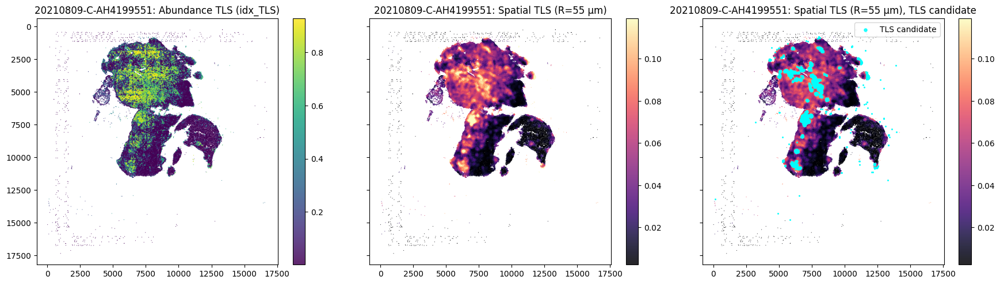

/home/lingyu/ssd2/Python/Hist2Pheno/data/Visium/NPC/pred_uni2_A5_bestmlp_paired_v2_seed42/figures/20210809-C-AH4199551_SRI_abundance_vs_spatial.pdf


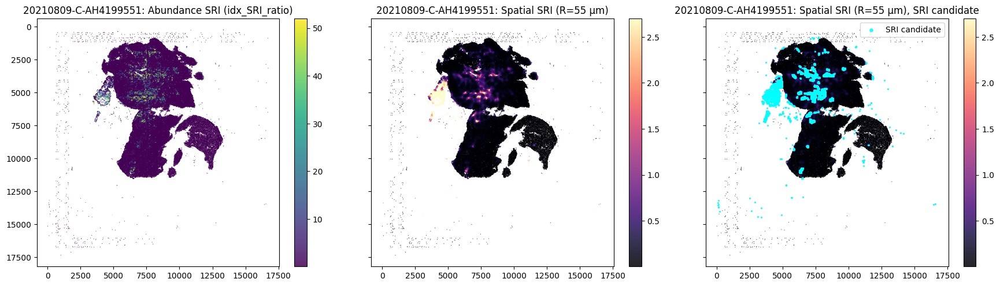

/home/lingyu/ssd2/Python/Hist2Pheno/data/Visium/NPC/pred_uni2_A5_bestmlp_paired_v2_seed42/figures/20210809-C-AH4199551_TNI_abundance_vs_spatial.pdf


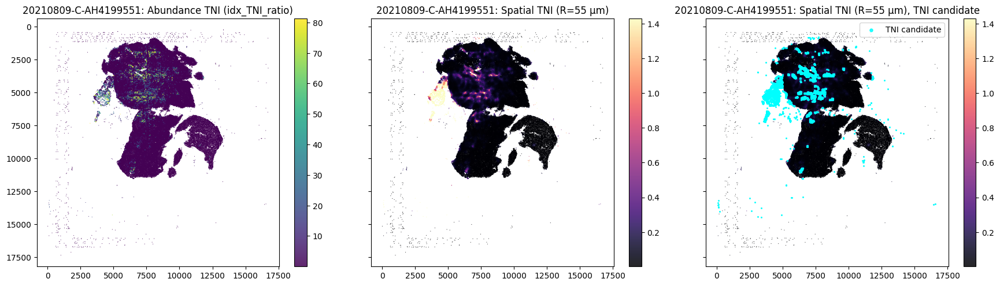

In [10]:
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

fig_dir = PRED_ROOT / "figures"
fig_dir.mkdir(parents=True, exist_ok=True)


quant_rows = [tls_score_row(df, sample) for sample, df in niche_frames.items()]
tls_quant = pd.DataFrame(quant_rows)
tls_quant_path = fig_dir / "tls_score_summary.csv"
tls_quant.to_csv(tls_quant_path, index=False)
print(tls_quant_path)
display(tls_quant.round(3))

for sample, df in niche_frames.items():
    fig, axes = hdni.plot_tls_abundance_vs_spatial(
        df,
        sample,
        radius_um=TLS_RADIUS_UM,
        use_entropy=False,
        split_spatial_candidates=True,
        dpi=DPI,
        save_dpi=SAVE_DPI,
        point_size=0.15,
        candidate_size=1.2,
        save_path=None,
    )
    if SAVE_FIGURES:
        save_figure(fig, fig_dir / f"{sample}_TLS_abundance_vs_spatial.png")
    display(fig)
    plt.close(fig)

    for abundance_col, spatial_col, candidate_col, tag in (
        ("idx_SRI_ratio", "idx_SRI_spatial", "sri_candidate", "SRI"),
        ("idx_TNI_ratio", "idx_TNI_spatial", "tni_candidate", "TNI"),
    ):
        fig, axes = hdni.plot_tls_abundance_vs_spatial(
            df,
            sample,
            radius_um=TLS_RADIUS_UM,
            abundance_col=abundance_col,
            spatial_col=spatial_col,
            candidate_col=candidate_col,
            use_entropy=False,
            split_spatial_candidates=True,
            score_name=tag,
            dpi=DPI,
        save_dpi=SAVE_DPI,
        point_size=0.15,
            candidate_size=1.2,
            save_path=None,
        )
        if SAVE_FIGURES:
            save_figure(fig, fig_dir / f"{sample}_{tag}_abundance_vs_spatial.png")
        display(fig)
        plt.close(fig)
